In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/IMDB Dataset.csv")

print(df.shape)
df.head()

(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
print(df["sentiment"].value_counts())

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


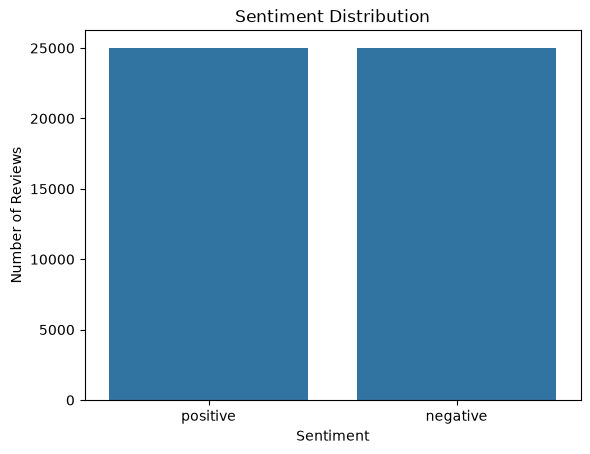

In [4]:
sns.countplot(data=df, x="sentiment")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [5]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

review       0
sentiment    0
dtype: int64
Duplicates: 418


In [6]:
df.dropna(inplace=True)
df.drop_duplicates(subset=["review"], inplace=True)
df.reset_index(drop=True, inplace=True)

C:\Users\SUPRATIK\AppData\Local\Temp\ipykernel_7932\4120510030.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)
C:\Users\SUPRATIK\AppData\Local\Temp\ipykernel_7932\4120510030.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(subset=["review"], inplace=True)
C:\Users\SUPRATIK\AppData\Local\Temp\ipykernel_7932\4120510030.py:3: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.reset_index(drop=True, inplace=True)


In [7]:
import re
from bs4 import BeautifulSoup

def clean_text(text):

    # Remove HTML tags
    text = BeautifulSoup(text, "html.parser").get_text()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [8]:
df["review"] = df["review"].apply(clean_text)

In [9]:
print(df["review"].iloc[0])

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.I would say the main appeal of the show is due to the fact that it goes where other shows wou

In [10]:
df["sentiment"] = df["sentiment"].map({
    "positive": 1,
    "negative": 0
})

In [11]:
print(df["sentiment"].value_counts())

sentiment
1    24884
0    24698
Name: count, dtype: int64


In [12]:
from sklearn.model_selection import train_test_split

X = df["review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 39665
Testing samples: 9917


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_vectors = tfidf.fit_transform(X_train)

X_test_vectors = tfidf.transform(X_test)

print("Training vector shape:", X_train_vectors.shape)
print("Testing vector shape:", X_test_vectors.shape)

Training vector shape: (39665, 10000)
Testing vector shape: (9917, 10000)


In [14]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    C=1.0,
    random_state=42
)

model.fit(X_train_vectors, y_train)

print("Model training completed!")

Model training completed!


In [16]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test_vectors)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9012806292225471

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.89      0.90      4940
           1       0.89      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



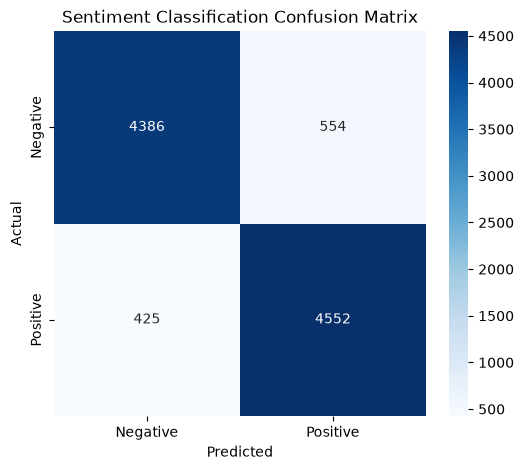

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Sentiment Classification Confusion Matrix")

plt.show()

In [18]:
import os
import joblib

os.makedirs("../artifacts", exist_ok=True)

joblib.dump(
    tfidf,
    "../artifacts/sentiment_vectorizer.pkl"
)

joblib.dump(
    model,
    "../artifacts/sentiment_model.pkl"
)

print("Sentiment model artifacts saved!")

Sentiment model artifacts saved!
